In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

print("pandas      :", pd.__version__)
print("numpy       :", np.__version__)
print("scikit-learn:", sklearn.__version__)

pandas      : 3.0.5
numpy       : 2.5.2
scikit-learn: 1.9.1


In [3]:
df = pd.read_csv("Project.csv")

print("Jumlah baris dan kolom:", df.shape)
df.head()

Jumlah baris dan kolom: (149116, 18)


,transaction_id,transaction_date,transaction_time,store_id,store_location,product_id,transaction_qty,unit_price,Total_Bill,product_category,product_type,product_detail,Size,Month Name,Day Name,Hour,Month,Day of Week
0,114301,01-06-2023,11:33:29,3,Astoria,45,1,3.0,3.0,Tea,Brewed herbal tea,Peppermint,Large,June,Thursday,11,6,3
1,115405,02-06-2023,11:18:24,3,Astoria,45,1,3.0,3.0,Tea,Brewed herbal tea,Peppermint,Large,June,Friday,11,6,4
2,115478,02-06-2023,12:02:45,3,Astoria,45,1,3.0,3.0,Tea,Brewed herbal tea,Peppermint,Large,June,Friday,12,6,4
3,116288,02-06-2023,19:39:47,3,Astoria,45,1,3.0,3.0,Tea,Brewed herbal tea,Peppermint,Large,June,Friday,19,6,4
4,116714,03-06-2023,12:24:57,3,Astoria,45,1,3.0,3.0,Tea,Brewed herbal tea,Peppermint,Large,June,Saturday,12,6,5


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 149116 entries, 0 to 149115
Data columns (total 18 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   transaction_id    149116 non-null  int64  
 1   transaction_date  149116 non-null  str    
 2   transaction_time  149116 non-null  str    
 3   store_id          149116 non-null  int64  
 4   store_location    149116 non-null  str    
 5   product_id        149116 non-null  int64  
 6   transaction_qty   149116 non-null  int64  
 7   unit_price        149116 non-null  float64
 8   Total_Bill        149116 non-null  float64
 9   product_category  149116 non-null  str    
 10  product_type      149116 non-null  str    
 11  product_detail    149116 non-null  str    
 12  Size              149116 non-null  str    
 13  Month Name        149116 non-null  str    
 14  Day Name          149116 non-null  str    
 15  Hour              149116 non-null  int64  
 16  Month             149116 non-nu

In [8]:
df.describe()
df.describe(include=["object", "string"])

,transaction_date,transaction_time,store_location,product_category,product_type,product_detail,Size,Month Name,Day Name
count,149116,149116,149116,149116,149116,149116,149116,149116,149116
unique,181,25762,3,9,29,45,4,6,7
top,19-06-2023,09:31:15,Hell's Kitchen,Coffee,Brewed Chai tea,Our Old Time Diner Blend,Regular,June,Friday
freq,1343,41,50735,58416,17183,8660,45789,35352,21701


In [9]:
print("Total missing value:", df.isnull().sum().sum())
print("Jumlah baris duplikat:", df.duplicated().sum())

Total missing value: 0
Jumlah baris duplikat: 0


In [10]:
print(df["product_category"].value_counts())
print()
print(df["Size"].value_counts())

product_category
Coffee                58416
Tea                   45449
Bakery                22796
Drinking Chocolate    11468
Flavours               6790
Coffee beans           1753
Loose Tea              1210
Branded                 747
Packaged Chocolate      487
Name: count, dtype: int64

Size
Regular        45789
Large          44885
Not Defined    44518
Small          13924
Name: count, dtype: int64


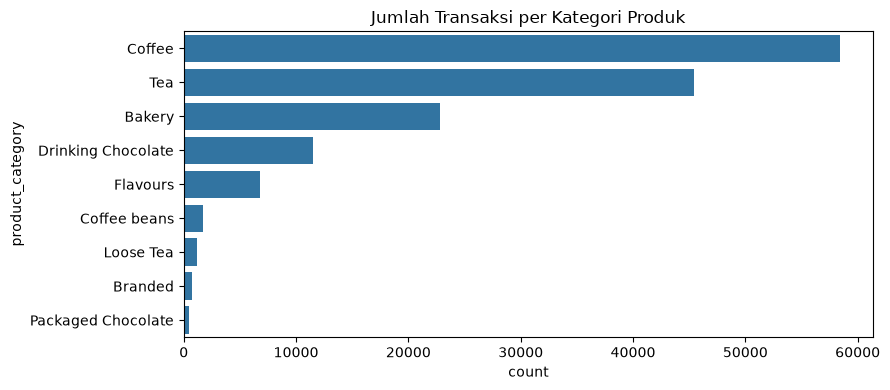

In [11]:
plt.figure(figsize=(9, 4))
sns.countplot(data=df, y="product_category", order=df["product_category"].value_counts().index)
plt.title("Jumlah Transaksi per Kategori Produk")
plt.tight_layout()
plt.show()

In [12]:
tanggal = pd.to_datetime(df["transaction_date"], format="%d-%m-%Y")
print("Tanggal awal :", tanggal.min())
print("Tanggal akhir:", tanggal.max())

Tanggal awal : 2023-01-01 00:00:00
Tanggal akhir: 2023-06-30 00:00:00


transaction_qty: 36 outlier (batas -0.50 - 3.50)
unit_price: 4212 outlier (batas 0.62 - 5.62)
Total_Bill: 3273 outlier (batas -1.50 - 10.50)


<Figure size 600x300 with 0 Axes>

<Figure size 600x300 with 0 Axes>

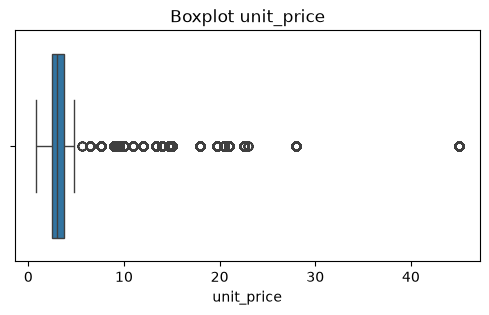

In [14]:
for kolom in ["transaction_qty", "unit_price", "Total_Bill"]:
    q1, q3 = df[kolom].quantile([0.25, 0.75])
    iqr = q3 - q1
    batas_bawah = q1 - 1.5 * iqr
    batas_atas = q3 + 1.5 * iqr
    jumlah = ((df[kolom] < batas_bawah) | (df[kolom] > batas_atas)).sum()
    print(f"{kolom}: {jumlah} outlier (batas {batas_bawah:.2f} - {batas_atas:.2f})")

    plt.figure(figsize=(6, 3))
sns.boxplot(x=df["unit_price"])
plt.title("Boxplot unit_price")
plt.show()

In [15]:
print("Total_Bill == qty x harga:", (df["transaction_qty"] * df["unit_price"] == df["Total_Bill"]).mean())
print(pd.crosstab(df["Month"], df["Month Name"]))

Total_Bill == qty x harga: 0.996781029534054
Month Name  April  February  January   June  March    May
Month                                                    
1               0         0    17314      0      0      0
2               0     16359        0      0      0      0
3               0         0        0      0  21229      0
4           25335         0        0      0      0      0
5               0         0        0      0      0  33527
6               0         0        0  35352      0      0


In [16]:
fitur = ["store_location", "transaction_qty", "Size", "Hour", "Month", "Day of Week"]
X = df[fitur]
y = df["product_category"]

print("Bentuk X:", X.shape)
print("Bentuk y:", y.shape)
X.head()

Bentuk X: (149116, 6)
Bentuk y: (149116,)


,store_location,transaction_qty,Size,Hour,Month,Day of Week
0,Astoria,1,Large,11,6,3
1,Astoria,1,Large,11,6,4
2,Astoria,1,Large,12,6,4
3,Astoria,1,Large,19,6,4
4,Astoria,1,Large,12,6,5


In [17]:
X = pd.get_dummies(X, columns=["store_location", "Size"], dtype=int)

print("Bentuk X setelah encoding:", X.shape)
print(list(X.columns))
X.head()

Bentuk X setelah encoding: (149116, 11)
['transaction_qty', 'Hour', 'Month', 'Day of Week', 'store_location_Astoria', "store_location_Hell's Kitchen", 'store_location_Lower Manhattan', 'Size_Large', 'Size_Not Defined', 'Size_Regular', 'Size_Small']


,transaction_qty,Hour,Month,Day of Week,store_location_Astoria,store_location_Hell's Kitchen,store_location_Lower Manhattan,Size_Large,Size_Not Defined,Size_Regular,Size_Small
0,1,11,6,3,1,0,0,1,0,0,0
1,1,11,6,4,1,0,0,1,0,0,0
2,1,12,6,4,1,0,0,1,0,0,0
3,1,19,6,4,1,0,0,1,0,0,0
4,1,12,6,5,1,0,0,1,0,0,0


In [19]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("X_train:", X_train.shape)
print("X_test :", X_test.shape)
print("y_train:", y_train.shape)
print("y_test :", y_test.shape)

proporsi = pd.concat(
    [y.value_counts(normalize=True),
     y_train.value_counts(normalize=True),
     y_test.value_counts(normalize=True)],
    axis=1, keys=["Semua", "Train", "Test"]
).round(4)
print(proporsi)

X_train: (119292, 11)
X_test : (29824, 11)
y_train: (119292,)
y_test : (29824,)
                     Semua   Train    Test
product_category                          
Coffee              0.3917  0.3917  0.3918
Tea                 0.3048  0.3048  0.3048
Bakery              0.1529  0.1529  0.1529
Drinking Chocolate  0.0769  0.0769  0.0769
Flavours            0.0455  0.0455  0.0455
Coffee beans        0.0118  0.0118  0.0118
Loose Tea           0.0081  0.0081  0.0081
Branded             0.0050  0.0050  0.0050
Packaged Chocolate  0.0033  0.0033  0.0033


In [20]:
from sklearn.preprocessing import StandardScaler

kolom_angka = ["transaction_qty", "Hour", "Month", "Day of Week"]

scaler = StandardScaler()
X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()

X_train_scaled[kolom_angka] = scaler.fit_transform(X_train[kolom_angka])
X_test_scaled[kolom_angka] = scaler.transform(X_test[kolom_angka])

print(X_train_scaled[kolom_angka].mean().round(3))
print(X_train_scaled[kolom_angka].std().round(3))

transaction_qty    0.0
Hour              -0.0
Month             -0.0
Day of Week       -0.0
dtype: float64
transaction_qty    1.0
Hour               1.0
Month              1.0
Day of Week        1.0
dtype: float64
